# PyTorch machine vision: classify handwritten digits with a CNN

This notebook follows the same **inspect → split → define a model → train → test** structure as the attached power-plant notebook. Here the inputs are images, and the output is one of ten digit classes (0–9), so we use a convolutional neural network (CNN) and classification accuracy instead of a fully connected regressor and MSE.

The [scikit-learn digits dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html) contains **1,797 grayscale 8×8 images**. It is bundled with scikit-learn, so running this notebook does **not** download data. Only `torch`, `scikit-learn`, `numpy`, and `matplotlib` are needed.

## 1. Load and view the images

Pixel values run from 0 to 16; dividing by 16 puts them in the range 0–1. PyTorch convolution layers expect images shaped `(examples, channels, height, width)`, so we add one channel dimension for these grayscale images.

Images: 1797, image shape: (8, 8), classes: 10


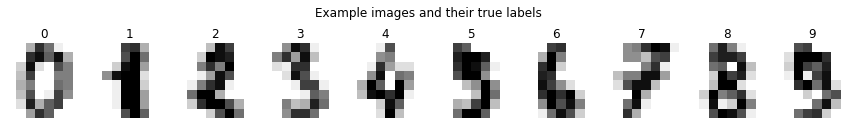

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

RNG = 10
torch.manual_seed(RNG)

digits = load_digits()
X = (digits.images / 16.0).astype(np.float32)  # (1797, 8, 8), sklearn uses 0-16 as pixel values.
y = digits.target.astype(np.int64)             # digit labels 0-9
print(f"Images: {len(X)}, image shape: {X.shape[1:]}, classes: {len(np.unique(y))}")

fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for i, ax in enumerate(axes):
    ax.imshow(X[i], cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(str(y[i]))
    ax.axis("off")
fig.suptitle("Example images and their true labels")
plt.tight_layout()
plt.show()


## 2. Split the images

Use **60% training / 20% validation / 20% test**, as in the reference notebook. `stratify` keeps the ten classes represented in each split. The test images are held aside until the final evaluation.

In [3]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RNG, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=RNG, stratify=y_dev
)

def image_tensor(images):
    return torch.tensor(images[:, None, :, :])  # add grayscale channel

x_train, x_val, x_test = map(image_tensor, (X_train, X_val, X_test))
y_train = torch.tensor(y_train, dtype=torch.long)
y_val = torch.tensor(y_val, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

train_loader = DataLoader(
    TensorDataset(x_train, y_train), batch_size=64, shuffle=True,
    generator=torch.Generator().manual_seed(RNG)
)
print(f"Training: {len(x_train)}  Validation: {len(x_val)}  Test: {len(x_test)}")
print(f"One batch: {next(iter(train_loader))[0].shape}")


Training: 1077  Validation: 360  Test: 360
One batch: torch.Size([64, 1, 8, 8])


## 3. Define a small CNN

The first 3×3 convolution learns eight image filters; the second learns 16 filters from those features. ReLU adds nonlinearity after each convolution. A 2×2 max pool then reduces each 8×8 feature map to 4×4, and the final linear layer produces ten class scores. `CrossEntropyLoss` takes these raw scores, so there is no final softmax layer. The table printed below counts each layer's trainable weights and biases; ReLU, pooling, and flattening have zero parameters.

In [4]:
torch.manual_seed(RNG)
model = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.Conv2d(8, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(16 * 4 * 4, 10),
)
print(model)
print("\nTrainable parameters by layer (weights + biases):")
for i, layer in enumerate(model):
    count = sum(p.numel() for p in layer.parameters() if p.requires_grad)
    print(f"{i:>2}  {layer.__class__.__name__:<12} {count:>6}")
print(f"Total: {sum(p.numel() for p in model.parameters() if p.requires_grad)}")


Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU()
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Flatten(start_dim=1, end_dim=-1)
  (6): Linear(in_features=256, out_features=10, bias=True)
)

Trainable parameters by layer (weights + biases):
 0  Conv2d           80
 1  ReLU              0
 2  Conv2d         1168
 3  ReLU              0
 4  MaxPool2d         0
 5  Flatten           0
 6  Linear         2570
Total: 3818


## 4. Train with mini-batches

Each batch updates the weights once. We record training and validation loss and accuracy after each epoch. Accuracy is the fraction of images whose predicted digit matches the true digit.

Epoch  1/30: train accuracy 17.7%, validation accuracy 18.6%
Epoch  5/30: train accuracy 87.7%, validation accuracy 88.9%
Epoch 10/30: train accuracy 92.0%, validation accuracy 93.9%
Epoch 15/30: train accuracy 95.2%, validation accuracy 95.3%
Epoch 20/30: train accuracy 97.5%, validation accuracy 96.9%
Epoch 25/30: train accuracy 98.1%, validation accuracy 96.9%
Epoch 30/30: train accuracy 98.5%, validation accuracy 97.2%


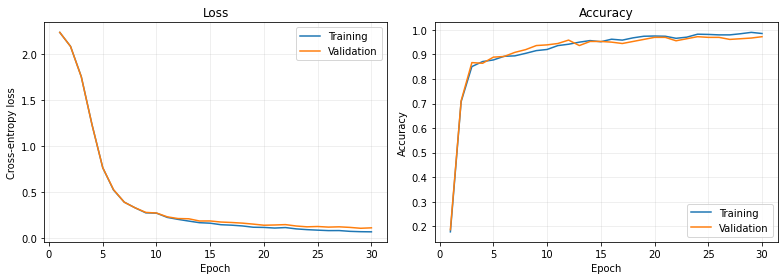

In [5]:
EPOCHS = 30
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_loss, val_loss, train_acc, val_acc = [], [], [], []

for epoch in range(1, EPOCHS + 1):
    model.train()
    for x_batch, y_batch in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(x_batch), y_batch)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        train_scores = model(x_train)
        val_scores = model(x_val)
        train_loss.append(loss_fn(train_scores, y_train).item())
        val_loss.append(loss_fn(val_scores, y_val).item())
        train_acc.append((train_scores.argmax(1) == y_train).float().mean().item())
        val_acc.append((val_scores.argmax(1) == y_val).float().mean().item())

    if epoch == 1 or epoch % 5 == 0:
        print(f"Epoch {epoch:2d}/{EPOCHS}: "
              f"train accuracy {train_acc[-1]:.1%}, "
              f"validation accuracy {val_acc[-1]:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, EPOCHS + 1), train_loss, label="Training")
axes[0].plot(range(1, EPOCHS + 1), val_loss, label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
axes[1].plot(range(1, EPOCHS + 1), train_acc, label="Training")
axes[1].plot(range(1, EPOCHS + 1), val_acc, label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 5. Test on unseen images

Compute test accuracy once, then display five correct and five incorrect test predictions. A red title marks an incorrect prediction.

Final validation accuracy: 97.2%
Held-out test accuracy:    95.8%


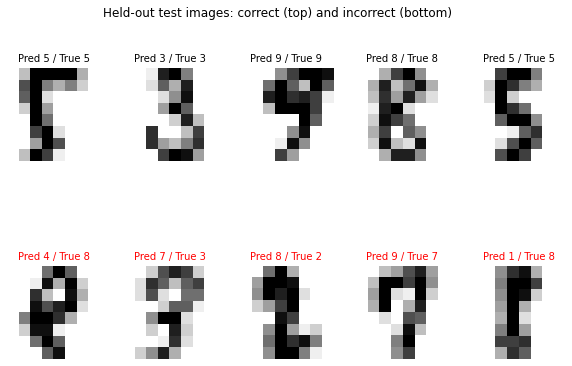

In [6]:
model.eval()
with torch.no_grad():
    test_prediction = model(x_test).argmax(1)
test_accuracy = (test_prediction == y_test).float().mean().item()
print(f"Final validation accuracy: {val_acc[-1]:.1%}")
print(f"Held-out test accuracy:    {test_accuracy:.1%}")

correct = torch.where(test_prediction == y_test)[0][:5].tolist()
incorrect = torch.where(test_prediction != y_test)[0][:5].tolist()
fig, axes = plt.subplots(2, 5, figsize=(10, 6))
for i, ax in zip(correct + incorrect, axes.flat):
    actual = y_test[i].item()
    predicted = test_prediction[i].item()
    ax.imshow(X_test[i], cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"Pred {predicted} / True {actual}",
                 color="black" if predicted == actual else "red", fontsize=10)
    ax.axis("off")
fig.suptitle("Held-out test images: correct (top) and incorrect (bottom)")
fig.subplots_adjust(top=0.88, hspace=0.55, wspace=0.25)
plt.show()


## 6. See what the convolution layers detect

The pictures below are **feature maps**: the responses produced when the trained convolutional kernels process one held-out image. They are shown **after ReLU and before max pooling**. Layer 1 produces 8 maps, and layer 2 produces 16 maps. These are image-dependent outputs, not pictures of the kernel weights themselves.

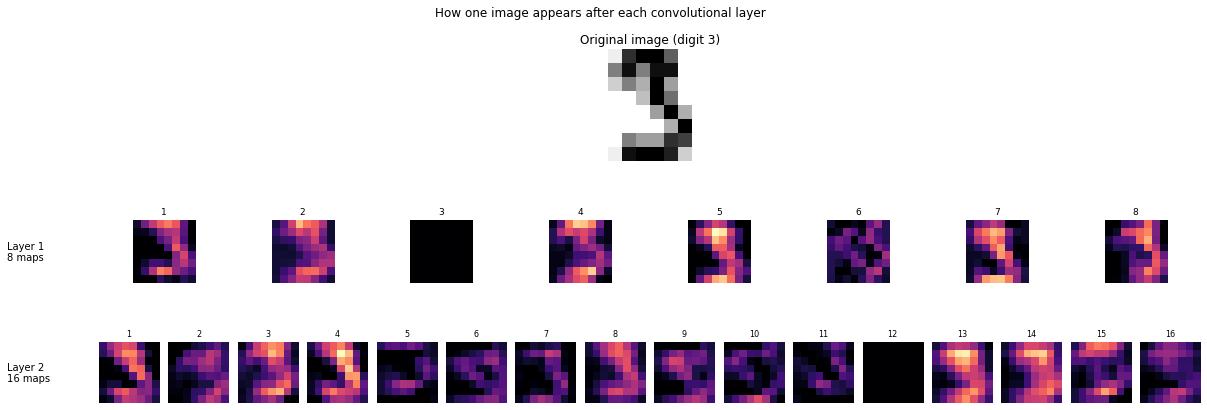

In [9]:
from matplotlib.gridspec import GridSpec

sample_index = 6
image = x_test[sample_index:sample_index + 1]
model.eval()
with torch.no_grad():
    layer1_output = model[1](model[0](image))
    layer2_output = model[3](model[2](layer1_output))
    layer1_maps = layer1_output[0].numpy()
    layer2_maps = layer2_output[0].numpy()

fig = plt.figure(figsize=(17, 6))
grid = GridSpec(3, 16, figure=fig, height_ratios=[1.8, 1, 1],
                left=0.09, right=0.99, top=0.88, bottom=0.06,
                hspace=0.75, wspace=0.15)

original_ax = fig.add_subplot(grid[0, 6:10])
original_ax.imshow(X_test[sample_index], cmap="gray_r", vmin=0, vmax=1)
original_ax.set_title(f"Original image (digit {y_test[sample_index].item()})")
original_ax.axis("off")

first_axes = []
for i in range(8):
    ax = fig.add_subplot(grid[1, 2*i:2*i+2])
    ax.imshow(layer1_maps[i], cmap="magma", vmin=0,
              vmax=layer1_maps.max(), interpolation="nearest")
    ax.set_title(str(i + 1), fontsize=9)
    ax.axis("off")
    first_axes.append(ax)

second_axes = []
for i in range(16):
    ax = fig.add_subplot(grid[2, i])
    ax.imshow(layer2_maps[i], cmap="magma", vmin=0,
              vmax=layer2_maps.max(), interpolation="nearest")
    ax.set_title(str(i + 1), fontsize=8)
    ax.axis("off")
    second_axes.append(ax)

for name, axes in [("Layer 1\n8 maps", first_axes),
                   ("Layer 2\n16 maps", second_axes)]:
    position = axes[0].get_position()
    fig.text(0.015, position.y0 + position.height / 2, name,
             va="center", fontsize=10)
fig.suptitle("How one image appears after each convolutional layer")
plt.show()


## What to try next

Try increasing the filters from 8 and 16 to 16 and 32. If you do, update the second convolution's input channels and the linear layer's input size to `32 * 4 * 4`. Compare validation accuracy before using the test set again.